# Notebook 5 — A **reverse (inverse) PINN** for the drag problem
### Discovering the hidden drag coefficient k from noisy data · research log

**The goal that makes this notebook feel like real research.** Suppose I film a projectile
flying through the air and extract a handful of noisy $(x,y)$ positions over time. I know it
was thrown, and roughly how — but I do **not** know the object's **drag coefficient $k$**, a
property of its shape and the air. Can a PINN look at those noisy points and *tell me $k$*?

This is the classic inverse problem PINNs were popularised for: **discovering an unknown
coefficient of a differential equation from data**. In Notebook 4 I recovered launch
conditions for the simple parabola; here I recover a coefficient buried inside a **nonlinear**
equation of motion that has no closed-form solution — which is where this technique really
earns its keep, because there's no formula to invert by hand.

**My setup.** The drag equations of motion from Notebook 3 are
$$ \ddot x = -k\,v\,\dot x,\qquad \ddot y = -g-k\,v\,\dot y,\qquad v=\sqrt{\dot x^2+\dot y^2}. $$
I assume I know how the object was launched (its initial velocity) but **not** $k$. I make
$k$ a **trainable parameter**, train a time-domain network $(t)\mapsto(x,y)$ to fit the noisy
data while obeying these equations, and read off the $k$ that gradient descent settles on.

**A detail I'm careful about:** $k$ must stay non-negative (negative drag is unphysical), so I
don't optimise $k$ directly — I optimise an unconstrained number and pass it through a
`softplus` so the result is always $\ge 0$. Small thing, but it stops the optimiser wandering
into nonsense.

## Setup
PyTorch for the network/autograd, NumPy for the RK4 simulator I use to *manufacture* the noisy
data, Matplotlib for plots.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
torch.manual_seed(0)
np.random.seed(0)
g = 9.81

Device: cpu


## Manufacturing the noisy 3-D observations with RK4

I now extend the inverse problem from Notebook 5 into three dimensions.

Instead of observing only $(x,y)$, I assume I can obtain noisy measurements of all three projectile coordinates $(x,y,z)$ at known times.

I use the 3-D crosswind dynamics developed in Notebook 6 to generate the synthetic measurements.

**The hidden parameters are:**
- Launch velocity: $u=30$ m/s
- Elevation angle: $\theta=45^\circ$
- Crosswind: $w_z=6$ m/s

I keep the azimuth at $0^\circ$, drag coefficient at $k=0.012$, and downrange wind at zero.

I sample 20 points along the RK4 trajectory and add Gaussian measurement noise to each position coordinate.

The inverse PINN will attempt to recover $u$, $\theta$ and $w_z$ without receiving their true values as training inputs.

In [2]:
# ── 3-D projectile dynamics with crosswind ────────────────────────────────────
# State: [x, y, z, vx, vy, vz]
# Wind:  [wx, wy, wz]

def deriv3d(s, k, wind):
    x, y, z, vx, vy, vz = s
    wx, wy, wz = wind

    # Velocity relative to the surrounding air
    vrx = vx - wx
    vry = vy - wy
    vrz = vz - wz

    vrel = np.sqrt(vrx**2 + vry**2 + vrz**2)

    # Quadratic aerodynamic drag
    ax = -k * vrel * vrx
    ay = -g - k * vrel * vry
    az = -k * vrel * vrz

    return np.array([vx, vy, vz, ax, ay, az])


# ── One RK4 integration step ──────────────────────────────────────────────────

def rk4_step3d(s, dt, k, wind):
    k1 = deriv3d(s, k, wind)
    k2 = deriv3d(s + dt/2 * k1, k, wind)
    k3 = deriv3d(s + dt/2 * k2, k, wind)
    k4 = deriv3d(s + dt * k3, k, wind)

    return s + dt/6 * (k1 + 2*k2 + 2*k3 + k4)


# ── Integrate until the projectile lands ──────────────────────────────────────

def integrate3d(u, theta_deg, phi_deg, k, wind,
                dt=0.002, t_max=20.0):

    th = np.radians(theta_deg)
    ph = np.radians(phi_deg)

    vx0 = u * np.cos(th) * np.cos(ph)
    vy0 = u * np.sin(th)
    vz0 = u * np.cos(th) * np.sin(ph)

    s = np.array([0., 0., 0., vx0, vy0, vz0])

    T = [0.]
    S = [s.copy()]
    t = 0.

    while t < t_max:

        sn = rk4_step3d(s, dt, k, wind)

        # Detect landing
        if sn[1] < 0 and s[1] >= 0:

            frac = s[1] / (s[1] - sn[1])
            s_land = s + frac * (sn - s)

            t += frac * dt

            T.append(t)
            S.append(s_land)
            break

        s = sn
        t += dt

        T.append(t)
        S.append(s.copy())

    if t >= t_max and S[-1][1] > 0:
        raise RuntimeError("Projectile did not land within t_max.")

    return np.array(T), np.array(S)


# ═══ HIDDEN GROUND-TRUTH PARAMETERS ═══════════════════════════════════════════

u_true = 30.0
theta_true = 45.0
phi_true = 0.0

k_true = 0.012
wx_true = 0.0
wz_true = 6.0

wind_true = (wx_true, 0.0, wz_true)


# Generate the complete RK4 trajectory
T, S = integrate3d(
    u_true,
    theta_true,
    phi_true,
    k_true,
    wind_true
)

X = S[:, 0]
Y = S[:, 1]
Z = S[:, 2]


# ═══ GENERATE NOISY POSITION OBSERVATIONS ═════════════════════════════════════

N = 20
noise_std = 0.3

rng = np.random.default_rng(42)

idx = np.linspace(0, len(T)-1, N).astype(int)

t_obs = T[idx]

x_obs = X[idx] + rng.normal(0, noise_std, N)
y_obs = Y[idx] + rng.normal(0, noise_std, N)
z_obs = Z[idx] + rng.normal(0, noise_std, N)


# ═══ NORMALISATION SCALES ═════════════════════════════════════════════════════

T_ref = float(T[-1])

x_scale = float(np.max(np.abs(X)))
y_scale = float(np.max(np.abs(Y)))
z_scale = float(np.max(np.abs(Z)))

print("Synthetic 3-D dataset generated.")
print(f"Number of observations : {N}")
print(f"Flight time             : {T_ref:.3f} s")
print(f"Downrange distance      : {X[-1]:.2f} m")
print(f"Maximum height          : {Y.max():.2f} m")
print(f"Crossrange displacement : {Z[-1]:.2f} m")

print(f"\nPosition scales: x={x_scale:.2f}, "
      f"y={y_scale:.2f}, z={z_scale:.2f}")

# Ground truth is shown for validation only, not supplied to the model.
print("\nHidden parameters (evaluation only):")
print(f"u     = {u_true} m/s")
print(f"theta = {theta_true} degrees")
print(f"wz    = {wz_true} m/s")

Synthetic 3-D dataset generated.
Number of observations : 20
Flight time             : 3.627 s
Downrange distance      : 51.51 m
Maximum height          : 16.27 m
Crossrange displacement : 7.19 m

Position scales: x=51.51, y=16.27, z=7.19

Hidden parameters (evaluation only):
u     = 30.0 m/s
theta = 45.0 degrees
wz    = 6.0 m/s


## The 3-D position data I am given

The inverse PINN receives only the 20 noisy position measurements and their corresponding timestamps.

I visualise the observations in three dimensions to understand how the crosswind affects the projectile's ground track.

The true RK4 trajectory is retained for validation, but it is not used directly in the inverse model's data loss.

The crossrange coordinate $z$ is particularly important: with zero initial azimuth, its displacement is generated by the crosswind acting through aerodynamic drag.

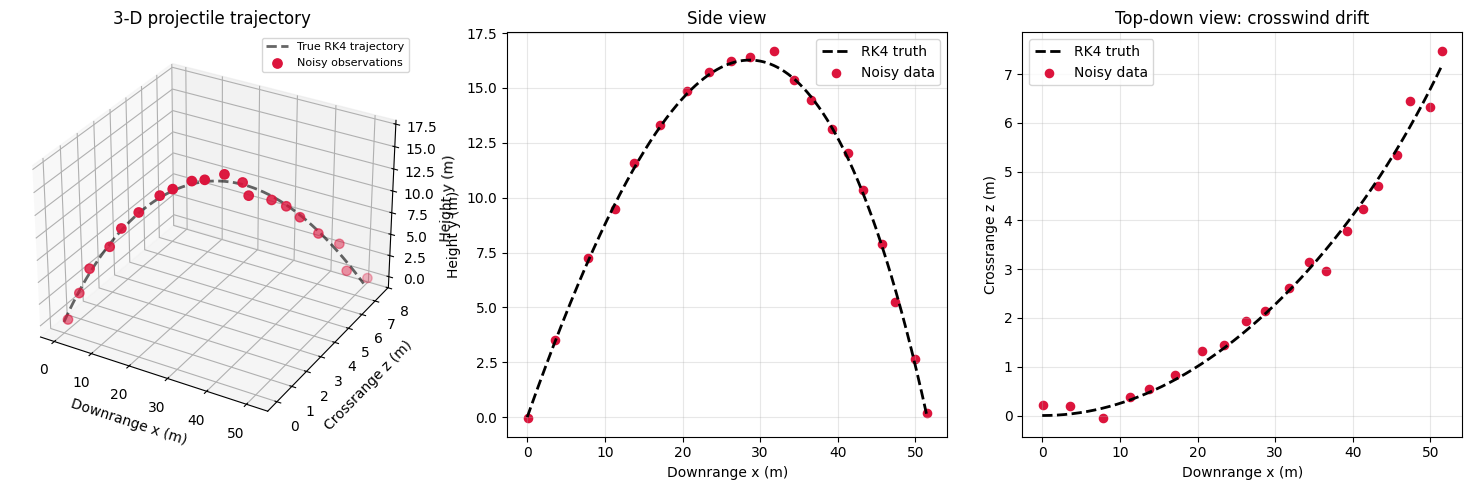

In [3]:
# ── Visualise the synthetic 3-D observations ──────────────────────────────────

fig = plt.figure(figsize=(15, 5))

# 3-D trajectory
ax1 = fig.add_subplot(131, projection='3d')

ax1.plot(
    X, Z, Y,
    'k--', lw=2, alpha=0.6,
    label='True RK4 trajectory'
)

ax1.scatter(
    x_obs, z_obs, y_obs,
    color='crimson', s=45,
    label='Noisy observations'
)

ax1.set_xlabel('Downrange x (m)')
ax1.set_ylabel('Crossrange z (m)')
ax1.set_zlabel('Height y (m)')
ax1.set_title('3-D projectile trajectory')
ax1.legend(fontsize=8)


# Side view
ax2 = fig.add_subplot(132)

ax2.plot(X, Y, 'k--', lw=2, label='RK4 truth')
ax2.scatter(x_obs, y_obs, color='crimson', s=35,
            label='Noisy data')

ax2.set_xlabel('Downrange x (m)')
ax2.set_ylabel('Height y (m)')
ax2.set_title('Side view')
ax2.legend()
ax2.grid(True, alpha=0.3)


# Top-down view
ax3 = fig.add_subplot(133)

ax3.plot(X, Z, 'k--', lw=2, label='RK4 truth')
ax3.scatter(x_obs, z_obs, color='crimson', s=35,
            label='Noisy data')

ax3.set_xlabel('Downrange x (m)')
ax3.set_ylabel('Crossrange z (m)')
ax3.set_title('Top-down view: crosswind drift')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Network + the three trainable physical parameters

I now extend the inverse network to predict the projectile's three-dimensional position as a function of time:

$$t\longrightarrow(x_{\mathrm{norm}},y_{\mathrm{norm}},z_{\mathrm{norm}})$$

The network receives time and returns three normalised position coordinates.

Unlike Notebook 5, where only the drag coefficient was unknown, I now have three unknown physical parameters:

- Initial launch velocity $u$
- Elevation angle $\theta$
- Crosswind velocity $w_z$

The drag coefficient $k=0.012$ is assumed known.

I optimise these three parameters jointly with the network weights.

To keep the estimates physically meaningful, I use bounded transformations:
- $u$ is constrained between 10 and 40 m/s.
- $\theta$ is constrained between 20° and 70°.
- $w_z$ is constrained between -12 and 12 m/s.

The initial guesses are deliberately different from the hidden ground truth.

The network uses Tanh activations, as in Notebook 5, so its derivatives remain smooth for the physics loss.

In [4]:
# ── Convert observations into PyTorch tensors ─────────────────────────────────

to = torch.tensor(
    t_obs, dtype=torch.float32, device=device
).unsqueeze(1)

xo = torch.tensor(
    x_obs, dtype=torch.float32, device=device
).unsqueeze(1) / x_scale

yo = torch.tensor(
    y_obs, dtype=torch.float32, device=device
).unsqueeze(1) / y_scale

zo = torch.tensor(
    z_obs, dtype=torch.float32, device=device
).unsqueeze(1) / z_scale


# ── 3-D fully connected neural network ────────────────────────────────────────

class FCN(nn.Module):

    def __init__(self, N_HIDDEN=48, N_LAYERS=4):
        super().__init__()

        layers = [nn.Linear(1, N_HIDDEN), nn.Tanh()]

        for _ in range(N_LAYERS - 1):
            layers += [
                nn.Linear(N_HIDDEN, N_HIDDEN),
                nn.Tanh()
            ]

        layers += [nn.Linear(N_HIDDEN, 3)]

        self.net = nn.Sequential(*layers)

    def forward(self, t):
        return self.net(t / T_ref)


net = FCN().to(device)


# ── Trainable inverse parameters ──────────────────────────────────────────────

# Bounded parameter transformations

u_raw = torch.nn.Parameter(
    torch.tensor(0.6931, device=device)
)

theta_raw = torch.nn.Parameter(
    torch.tensor(0.0, device=device)
)

wz_raw = torch.nn.Parameter(
    torch.tensor(0.1682, device=device)
)


def u_value():
    return 10.0 + 30.0 * torch.sigmoid(u_raw)


def theta_value():
    return 20.0 + 50.0 * torch.sigmoid(theta_raw)


def wz_value():
    return 12.0 * torch.tanh(wz_raw)


# Known physical parameters
k_known = 0.012
phi_known = 0.0
wx_known = 0.0

# Initial guesses
print("Initial parameter estimates:")
print(f"u     = {u_value().item():.3f} m/s")
print(f"theta = {theta_value().item():.3f} degrees")
print(f"wz    = {wz_value().item():.3f} m/s")


# ── Automatic differentiation helper ─────────────────────────────────────────

def d(out, t):
    return torch.autograd.grad(
        out,
        t,
        grad_outputs=torch.ones_like(out),
        create_graph=True
    )[0]

Initial parameter estimates:
u     = 30.000 m/s
theta = 45.000 degrees
wz    = 2.000 m/s


## The loss: match the data, obey the crosswind equations, respect the unknown launch

I now have three loss components.

**(1) Data loss**

The network must reproduce the observed three-dimensional positions:

$$\mathcal L_{\mathrm{data}}=
\operatorname{MSE}(\hat x,x_{\mathrm{obs}})
+\operatorname{MSE}(\hat y,y_{\mathrm{obs}})
+\operatorname{MSE}(\hat z,z_{\mathrm{obs}})$$

**(2) Physics loss**

The network's velocities and accelerations must satisfy the three-dimensional projectile equations with wind-relative quadratic drag.

The unknown crosswind $w_z$ enters directly into the relative velocity and therefore into all three acceleration equations.

**(3) Initial-condition loss**

The initial position is known to be the origin, but the initial velocity is unknown. I enforce:

$$v_x(0)=u\cos\theta,\quad
v_y(0)=u\sin\theta,\quad
v_z(0)=0$$

Here, $u$ and $\theta$ are trainable parameters rather than fixed values.

The three unknown physical parameters are therefore connected to the observed trajectory through both the initial conditions and the physics residuals.

All position measurements are normalised using their respective reference scales, and physics residuals are normalised by gravity.

In [5]:
# ── Initial time ──────────────────────────────────────────────────────────────

t0 = torch.zeros(
    1, 1, device=device, requires_grad=True
)


def compute_losses():

    # ═════════════════════════════════════════════════════════════════════════
    # (1) DATA LOSS
    # ═════════════════════════════════════════════════════════════════════════

    out = net(to)

    x_pred = out[:, 0:1]
    y_pred = out[:, 1:2]
    z_pred = out[:, 2:3]

    loss_data = (
        torch.mean((x_pred - xo)**2)
        + torch.mean((y_pred - yo)**2)
        + torch.mean((z_pred - zo)**2)
    )


    # ═════════════════════════════════════════════════════════════════════════
    # (2) PHYSICS LOSS
    # ═════════════════════════════════════════════════════════════════════════

    # Random collocation points throughout the flight
    tc = (
        torch.rand(256, 1, device=device) * T_ref
    ).requires_grad_(True)

    oc = net(tc)

    xc = oc[:, 0:1]
    yc = oc[:, 1:2]
    zc = oc[:, 2:3]

    # Physical velocities
    vx = d(xc, tc) * x_scale
    vy = d(yc, tc) * y_scale
    vz = d(zc, tc) * z_scale

    # Physical accelerations
    ax = d(vx, tc)
    ay = d(vy, tc)
    az = d(vz, tc)

    # Unknown crosswind
    wz = wz_value()

    # Relative air velocity
    vrx = vx - wx_known
    vry = vy
    vrz = vz - wz

    vrel = torch.sqrt(
        vrx**2 + vry**2 + vrz**2 + 1e-9
    )

    # Three-dimensional physics residuals
    Rx = ax + k_known * vrel * vrx

    Ry = ay + g + k_known * vrel * vry

    Rz = az + k_known * vrel * vrz

    loss_phys = torch.mean(
        (Rx/g)**2 + (Ry/g)**2 + (Rz/g)**2
    )


    # ═════════════════════════════════════════════════════════════════════════
    # (3) INITIAL CONDITION LOSS
    # ═════════════════════════════════════════════════════════════════════════

    o0 = net(t0)

    x0p = o0[:, 0:1]
    y0p = o0[:, 1:2]
    z0p = o0[:, 2:3]

    vx0p = d(x0p, t0) * x_scale
    vy0p = d(y0p, t0) * y_scale
    vz0p = d(z0p, t0) * z_scale

    # Trainable launch parameters
    u = u_value()
    theta = torch.deg2rad(theta_value())

    # Initial velocity components for zero azimuth
    vx0 = u * torch.cos(theta)
    vy0 = u * torch.sin(theta)
    vz0 = torch.zeros_like(vx0)

    loss_ic = (
        x0p.pow(2).mean()
        + y0p.pow(2).mean()
        + z0p.pow(2).mean()
        + ((vx0p - vx0)/40.0).pow(2).mean()
        + ((vy0p - vy0)/40.0).pow(2).mean()
        + ((vz0p - vz0)/40.0).pow(2).mean()
    )

    return loss_data, loss_phys, loss_ic

## Training — watching the launch parameters and crosswind emerge from the data

I jointly optimise the network weights and the three unknown physical parameters using Adam.

I retain the same general training strategy as Notebook 5:
- Adam optimiser with an initial learning rate of $3\times10^{-3}$.
- Cosine-annealed learning rate.
- Weighted data, physics and initial-condition losses.

At regular intervals, I record the estimated launch velocity, elevation angle and crosswind.

The objective is not simply to minimise the trajectory fitting error. The recovered physical parameters must also approach their known hidden values.

In [6]:
# ── Joint optimisation of network and physical parameters ─────────────────────

optimizer = torch.optim.Adam(
    list(net.parameters()) + [u_raw, theta_raw, wz_raw],
    lr=3e-3
)

num_epochs = 6000

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-5
)

# Training history
hist_total = []
hist_data = []
hist_phys = []
hist_ic = []

hist_u = []
hist_theta = []
hist_wz = []

print(
    f"{'epoch':>6} {'loss':>10} {'data':>10} "
    f"{'phys':>10} {'IC':>10} "
    f"{'u':>8} {'theta':>8} {'wz':>8}"
)

for epoch in range(num_epochs):

    optimizer.zero_grad()

    loss_data, loss_phys, loss_ic = compute_losses()

    loss = (
        5.0 * loss_data
        + 2.0 * loss_phys
        + 10.0 * loss_ic
    )

    loss.backward()

    optimizer.step()
    scheduler.step()

    # Record losses
    hist_total.append(loss.item())
    hist_data.append(loss_data.item())
    hist_phys.append(loss_phys.item())
    hist_ic.append(loss_ic.item())

    # Record parameter estimates
    hist_u.append(u_value().item())
    hist_theta.append(theta_value().item())
    hist_wz.append(wz_value().item())

    if epoch % 600 == 0 or epoch == num_epochs - 1:

        print(
            f"{epoch:>6} "
            f"{loss.item():>10.3e} "
            f"{loss_data.item():>10.3e} "
            f"{loss_phys.item():>10.3e} "
            f"{loss_ic.item():>10.3e} "
            f"{u_value().item():>8.3f} "
            f"{theta_value().item():>8.3f} "
            f"{wz_value().item():>8.3f}"
        )


# ── Final recovered parameters ────────────────────────────────────────────────

u_est = u_value().item()
theta_est = theta_value().item()
wz_est = wz_value().item()

print("\nINVERSE CROSSWIND PINN RESULTS")
print("-"*45)

print(f"Launch velocity : {u_est:.4f} m/s "
      f"(true: {u_true:.4f})")

print(f"Launch angle    : {theta_est:.4f} deg "
      f"(true: {theta_true:.4f})")

print(f"Crosswind       : {wz_est:.4f} m/s "
      f"(true: {wz_true:.4f})")

print("-"*45)

print(f"Velocity error  : {abs(u_est-u_true)/u_true*100:.2f}%")
print(f"Angle error     : {abs(theta_est-theta_true)/theta_true*100:.2f}%")
print(f"Wind error      : {abs(wz_est-wz_true)/abs(wz_true)*100:.2f}%")

 epoch       loss       data       phys         IC        u    theta       wz
     0  1.466e+01  1.189e+00  1.007e+00  6.703e-01   29.980   44.963    2.035
   600  5.874e-03  1.033e-03  2.709e-04  1.674e-05   29.698   44.920    5.936
  1200  5.391e-03  1.018e-03  1.365e-04  2.689e-06   29.950   45.126    6.033
  1800  6.310e-03  1.058e-03  1.111e-04  7.999e-05   30.029   45.070    6.052
  2400  5.314e-03  1.021e-03  8.977e-05  2.859e-06   30.047   45.058    6.069
  3000  5.271e-03  1.016e-03  8.390e-05  2.248e-06   30.051   45.056    6.071
  3600  5.277e-03  1.015e-03  8.943e-05  2.398e-06   30.052   45.056    6.070
  4200  5.271e-03  1.015e-03  8.815e-05  2.075e-06   30.053   45.056    6.068
  4800  5.268e-03  1.015e-03  8.646e-05  2.260e-06   30.053   45.056    6.073
  5400  5.265e-03  1.015e-03  8.563e-05  2.025e-06   30.053   45.056    6.071
  5999  5.251e-03  1.014e-03  7.946e-05  2.061e-06   30.053   45.056    6.070

INVERSE CROSSWIND PINN RESULTS
--------------------------------

## Did the three unknown parameters converge to the hidden truth?

I track the estimated launch velocity, elevation angle and crosswind velocity throughout training.

The dashed horizontal lines represent the known parameters used to manufacture the synthetic observations.

A successful inverse PINN should show all three estimates converging toward their respective ground-truth values, even though these values were not supplied during training.

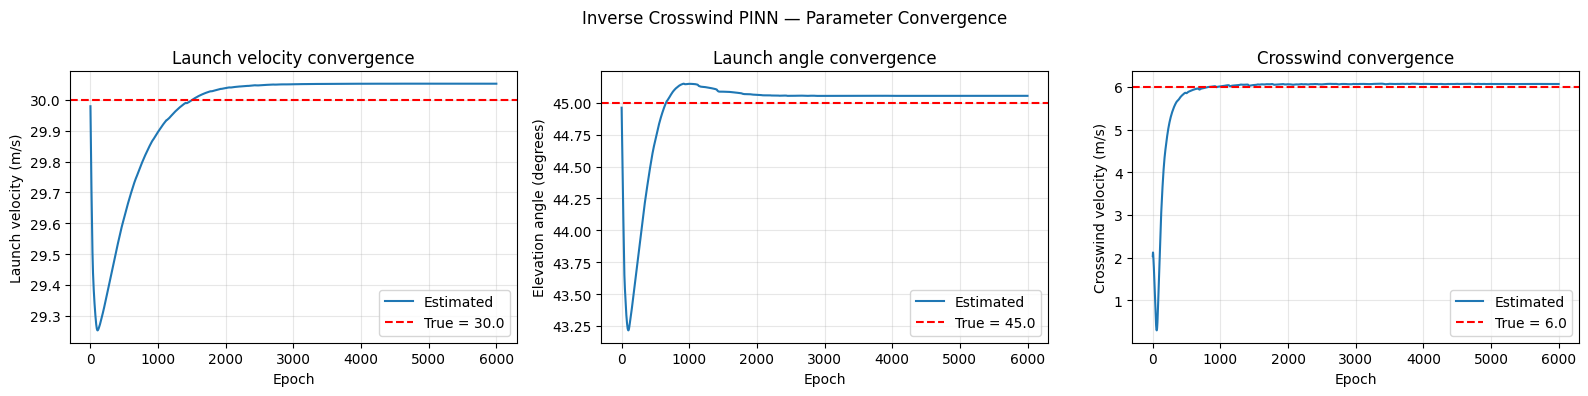

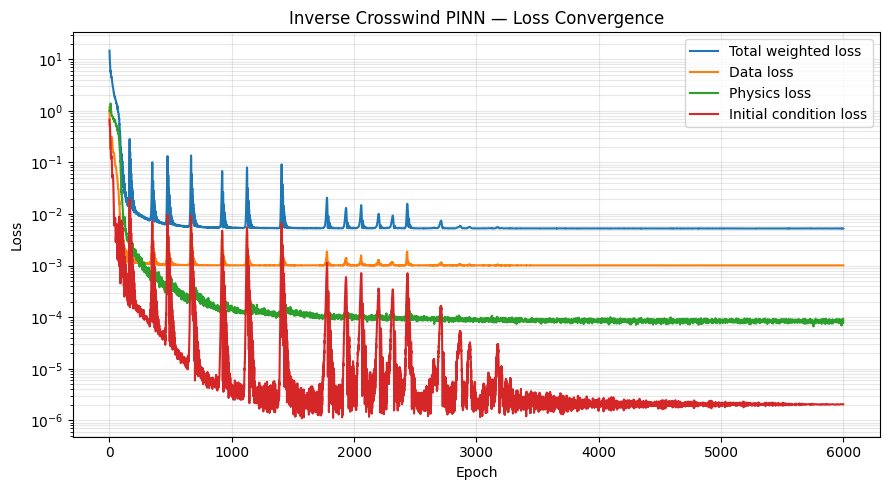

In [7]:
# ── Parameter convergence plots ───────────────────────────────────────────────

epochs = np.arange(len(hist_u))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Launch velocity
axes[0].plot(epochs, hist_u, label='Estimated')
axes[0].axhline(
    u_true, color='red', linestyle='--',
    label=f'True = {u_true}'
)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Launch velocity (m/s)')
axes[0].set_title('Launch velocity convergence')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Launch angle
axes[1].plot(epochs, hist_theta, label='Estimated')
axes[1].axhline(
    theta_true, color='red', linestyle='--',
    label=f'True = {theta_true}'
)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Elevation angle (degrees)')
axes[1].set_title('Launch angle convergence')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Crosswind
axes[2].plot(epochs, hist_wz, label='Estimated')
axes[2].axhline(
    wz_true, color='red', linestyle='--',
    label=f'True = {wz_true}'
)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Crosswind velocity (m/s)')
axes[2].set_title('Crosswind convergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('Inverse Crosswind PINN — Parameter Convergence')
plt.tight_layout()
plt.show()


# ── Loss convergence ──────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(hist_total, label='Total weighted loss')
ax.plot(hist_data, label='Data loss')
ax.plot(hist_phys, label='Physics loss')
ax.plot(hist_ic, label='Initial condition loss')

ax.set_yscale('log')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Inverse Crosswind PINN — Loss Convergence')
ax.legend()
ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

## The recovered 3-D trajectory vs RK4 truth vs noisy observations

After recovering the physical parameters, I evaluate the trained neural network throughout the complete flight interval.

I compare its predicted trajectory against the original RK4 trajectory and the noisy measurements.

This checks whether the recovered physical parameters produce a trajectory that is consistent with the observations and the governing equations.

I also calculate the coordinate-wise RMSE against the full RK4 trajectory, evaluated at the same timestamps.

TRAJECTORY RECONSTRUCTION ERRORS
---------------------------------------------
Downrange RMSE : 0.00781 m
Vertical RMSE  : 0.03686 m
Crossrange RMSE: 0.02477 m
Combined RMSE  : 0.04509 m


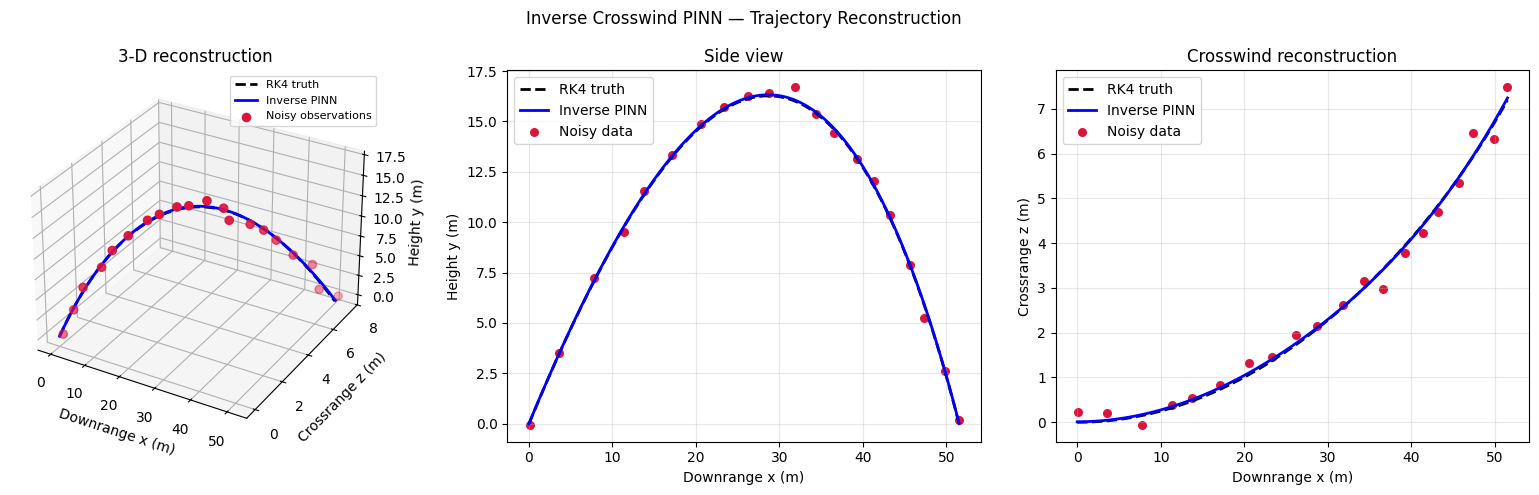

In [8]:
# ── Evaluate the trained inverse PINN ─────────────────────────────────────────

t_eval = torch.tensor(
    T, dtype=torch.float32, device=device
).reshape(-1, 1)

with torch.no_grad():
    pred = net(t_eval).cpu().numpy()

X_pred = pred[:, 0] * x_scale
Y_pred = pred[:, 1] * y_scale
Z_pred = pred[:, 2] * z_scale


# ═══ TRAJECTORY ERRORS ════════════════════════════════════════════════════════

rmse_x = np.sqrt(np.mean((X_pred - X)**2))
rmse_y = np.sqrt(np.mean((Y_pred - Y)**2))
rmse_z = np.sqrt(np.mean((Z_pred - Z)**2))

rmse_3d = np.sqrt(
    np.mean(
        (X_pred-X)**2 +
        (Y_pred-Y)**2 +
        (Z_pred-Z)**2
    )
)

print("TRAJECTORY RECONSTRUCTION ERRORS")
print("-"*45)
print(f"Downrange RMSE : {rmse_x:.5f} m")
print(f"Vertical RMSE  : {rmse_y:.5f} m")
print(f"Crossrange RMSE: {rmse_z:.5f} m")
print(f"Combined RMSE  : {rmse_3d:.5f} m")


# ═══ 3-D AND 2-D COMPARISON PLOTS ═════════════════════════════════════════════

fig = plt.figure(figsize=(16, 5))

# 3-D trajectory
ax1 = fig.add_subplot(131, projection='3d')

ax1.plot(
    X, Z, Y,
    'k--', lw=2,
    label='RK4 truth'
)

ax1.plot(
    X_pred, Z_pred, Y_pred,
    color='blue', lw=2,
    label='Inverse PINN'
)

ax1.scatter(
    x_obs, z_obs, y_obs,
    color='crimson', s=35,
    label='Noisy observations'
)

ax1.set_xlabel('Downrange x (m)')
ax1.set_ylabel('Crossrange z (m)')
ax1.set_zlabel('Height y (m)')
ax1.set_title('3-D reconstruction')
ax1.legend(fontsize=8)


# Side view
ax2 = fig.add_subplot(132)

ax2.plot(X, Y, 'k--', lw=2, label='RK4 truth')
ax2.plot(X_pred, Y_pred, 'b-', lw=2, label='Inverse PINN')
ax2.scatter(x_obs, y_obs, color='crimson', s=30,
            label='Noisy data')

ax2.set_xlabel('Downrange x (m)')
ax2.set_ylabel('Height y (m)')
ax2.set_title('Side view')
ax2.legend()
ax2.grid(alpha=0.3)


# Top-down view
ax3 = fig.add_subplot(133)

ax3.plot(X, Z, 'k--', lw=2, label='RK4 truth')
ax3.plot(X_pred, Z_pred, 'b-', lw=2, label='Inverse PINN')
ax3.scatter(x_obs, z_obs, color='crimson', s=30,
            label='Noisy data')

ax3.set_xlabel('Downrange x (m)')
ax3.set_ylabel('Crossrange z (m)')
ax3.set_title('Crosswind reconstruction')
ax3.legend()
ax3.grid(alpha=0.3)

plt.suptitle('Inverse Crosswind PINN — Trajectory Reconstruction')
plt.tight_layout()
plt.show()

## Crosswind sensitivity — can the inverse PINN recover different wind conditions?

A single successful parameter-recovery experiment does not establish that the inverse PINN works across different crosswind conditions.

I therefore evaluate the model at five different constant crosswind velocities:

$$w_z \in \{2,4,6,8,10\}\text{ m/s}$$

For each wind condition, I independently generate a synthetic trajectory using the RK4 simulator, add Gaussian measurement noise, and train a freshly initialized inverse PINN.

The launch velocity, elevation angle and drag coefficient remain fixed across all experiments.

I compare the estimated parameters against their known ground-truth values to evaluate how reliably the inverse PINN identifies the underlying physical conditions.

In [9]:
# ══════════════════════════════════════════════════════════════════════════════
# CROSSWIND SENSITIVITY EXPERIMENT
# ══════════════════════════════════════════════════════════════════════════════

wind_cases = [2.0, 4.0, 6.0, 8.0, 10.0]

N = 20
noise_std = 0.3
epochs_sensitivity = 3000

sensitivity_results = []


def run_wind_experiment(wind_value, seed):

    global T, S, X, Y, Z, T_ref
    global x_scale, y_scale, z_scale
    global t_obs, x_obs, y_obs, z_obs
    global to, xo, yo, zo
    global net, u_raw, theta_raw, wz_raw, t0
    global u_true, theta_true, wz_true
    global k_known, phi_known, wx_known

    # ── 1. Ground-truth parameters ────────────────────────────────────────────

    u_true = 30.0
    theta_true = 45.0
    wz_true = wind_value

    k_known = 0.012
    phi_known = 0.0
    wx_known = 0.0

    wind = (wx_known, 0.0, wz_true)

    # ── 2. Generate RK4 ground truth ──────────────────────────────────────────

    T, S = integrate3d(
        u_true, theta_true, phi_known,
        k_known, wind
    )

    X = S[:, 0]
    Y = S[:, 1]
    Z = S[:, 2]

    T_ref = float(T[-1])

    x_scale = float(np.max(np.abs(X)))
    y_scale = float(np.max(np.abs(Y)))
    z_scale = float(np.max(np.abs(Z)))

    # ── 3. Generate noisy observations ────────────────────────────────────────

    rng = np.random.default_rng(seed)

    idx = np.linspace(0, len(T)-1, N).astype(int)

    t_obs = T[idx]

    x_obs = X[idx] + rng.normal(0, noise_std, N)
    y_obs = Y[idx] + rng.normal(0, noise_std, N)
    z_obs = Z[idx] + rng.normal(0, noise_std, N)

    to = torch.tensor(
        t_obs, dtype=torch.float32, device=device
    ).reshape(-1, 1)

    xo = torch.tensor(
        x_obs, dtype=torch.float32, device=device
    ).reshape(-1, 1) / x_scale

    yo = torch.tensor(
        y_obs, dtype=torch.float32, device=device
    ).reshape(-1, 1) / y_scale

    zo = torch.tensor(
        z_obs, dtype=torch.float32, device=device
    ).reshape(-1, 1) / z_scale

    # ── 4. Fresh network and parameter initialization ─────────────────────────

    torch.manual_seed(seed)

    net = FCN().to(device)

    u_raw = torch.nn.Parameter(
        torch.tensor(0.6931, device=device)
    )

    theta_raw = torch.nn.Parameter(
        torch.tensor(0.0, device=device)
    )

    wz_raw = torch.nn.Parameter(
        torch.tensor(0.1682, device=device)
    )

    t0 = torch.zeros(
        1, 1, device=device, requires_grad=True
    )

    params = list(net.parameters()) + [
        u_raw, theta_raw, wz_raw
    ]

    # ── 5. Optimizer ──────────────────────────────────────────────────────────

    optimizer = torch.optim.Adam(
        params, lr=3e-3
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs_sensitivity,
        eta_min=1e-5
    )

    # ── 6. Train ──────────────────────────────────────────────────────────────

    for epoch in range(epochs_sensitivity):

        optimizer.zero_grad()

        ld, lp, lic = compute_losses()

        loss = 5.0*ld + 2.0*lp + 10.0*lic

        loss.backward()
        optimizer.step()
        scheduler.step()

    # ── 7. Recover parameters ─────────────────────────────────────────────────

    u_est = u_value().item()
    theta_est = theta_value().item()
    wz_est = wz_value().item()

    # ── 8. Evaluate trajectory reconstruction ─────────────────────────────────

    t_eval = torch.tensor(
        T, dtype=torch.float32, device=device
    ).reshape(-1, 1)

    with torch.no_grad():
        pred = net(t_eval).cpu().numpy()

    Xp = pred[:, 0] * x_scale
    Yp = pred[:, 1] * y_scale
    Zp = pred[:, 2] * z_scale

    rmse = np.sqrt(np.mean(
        (Xp-X)**2 + (Yp-Y)**2 + (Zp-Z)**2
    ))

    return {
        'True wind': wind_value,
        'Estimated wind': wz_est,
        'Wind error (%)': abs(wz_est-wind_value)/abs(wind_value)*100,
        'Estimated velocity': u_est,
        'Velocity error (%)': abs(u_est-u_true)/u_true*100,
        'Estimated angle': theta_est,
        'Angle error (%)': abs(theta_est-theta_true)/theta_true*100,
        'Trajectory RMSE (m)': rmse
    }


# ═══ RUN ALL FIVE CASES ═══════════════════════════════════════════════════════

for i, wind_value in enumerate(wind_cases):

    print(f"\nRunning crosswind case: {wind_value:.1f} m/s")

    result = run_wind_experiment(
        wind_value,
        seed=100+i
    )

    sensitivity_results.append(result)

    print(
        f"Recovered wind: {result['Estimated wind']:.4f} m/s | "
        f"Error: {result['Wind error (%)']:.2f}%"
    )

print("\nAll sensitivity experiments completed.")


Running crosswind case: 2.0 m/s
Recovered wind: 0.9266 m/s | Error: 53.67%

Running crosswind case: 4.0 m/s
Recovered wind: 3.5966 m/s | Error: 10.08%

Running crosswind case: 6.0 m/s
Recovered wind: 6.1383 m/s | Error: 2.30%

Running crosswind case: 8.0 m/s
Recovered wind: 8.0388 m/s | Error: 0.49%

Running crosswind case: 10.0 m/s
Recovered wind: 10.1354 m/s | Error: 1.35%

All sensitivity experiments completed.


In [10]:
import pandas as pd

results_df = pd.DataFrame(sensitivity_results)

print("CROSSWIND SENSITIVITY RESULTS")
display(results_df.round(4))

print("\nAverage crosswind estimation error:",
      f"{results_df['Wind error (%)'].mean():.3f}%")

print("Average trajectory RMSE:",
      f"{results_df['Trajectory RMSE (m)'].mean():.4f} m")

CROSSWIND SENSITIVITY RESULTS


,True wind,Estimated wind,Wind error (%),Estimated velocity,Velocity error (%),Estimated angle,Angle error (%),Trajectory RMSE (m)
0,2.0,0.9266,53.6699,30.0059,0.0196,45.0106,0.0236,0.1683
1,4.0,3.5966,10.0841,29.9607,0.1311,45.0595,0.1322,0.0788
2,6.0,6.1383,2.3045,30.0487,0.1624,45.0424,0.0941,0.1588
3,8.0,8.0388,0.4855,29.9861,0.0465,45.1527,0.3392,0.0851
4,10.0,10.1354,1.3544,30.1088,0.3627,45.0264,0.0586,0.1230



Average crosswind estimation error: 13.580%
Average trajectory RMSE: 0.1228 m


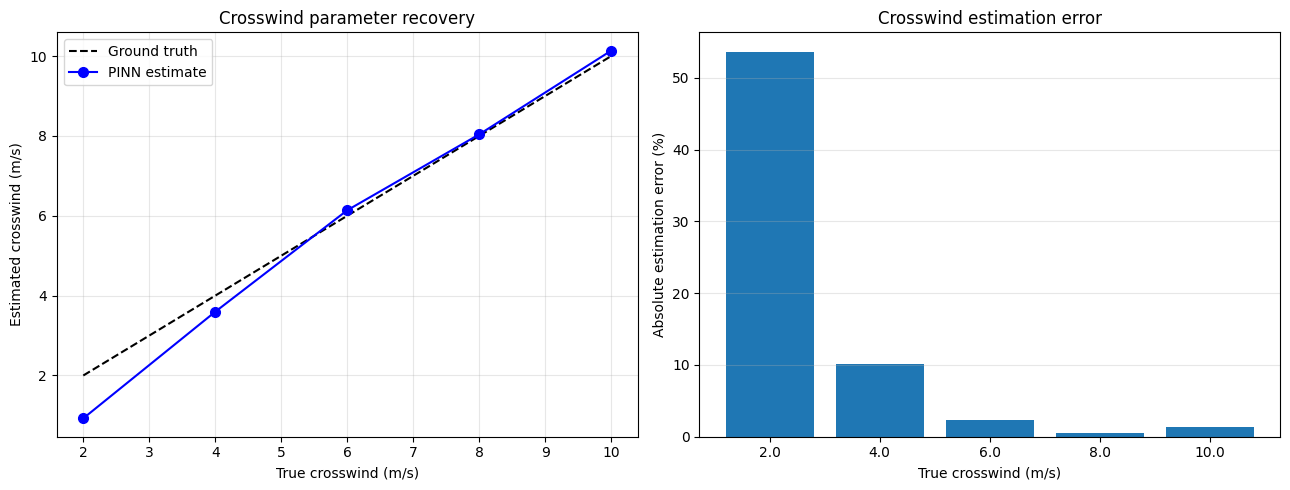

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Crosswind recovery
axes[0].plot(
    results_df['True wind'],
    results_df['True wind'],
    'k--', label='Ground truth'
)

axes[0].plot(
    results_df['True wind'],
    results_df['Estimated wind'],
    'bo-', markersize=7,
    label='PINN estimate'
)

axes[0].set_xlabel('True crosswind (m/s)')
axes[0].set_ylabel('Estimated crosswind (m/s)')
axes[0].set_title('Crosswind parameter recovery')
axes[0].legend()
axes[0].grid(alpha=0.3)


# Estimation error
axes[1].bar(
    results_df['True wind'].astype(str),
    results_df['Wind error (%)']
)

axes[1].set_xlabel('True crosswind (m/s)')
axes[1].set_ylabel('Absolute estimation error (%)')
axes[1].set_title('Crosswind estimation error')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()